In [86]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [87]:
df = pd.read_csv("winequality-red.csv")

df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


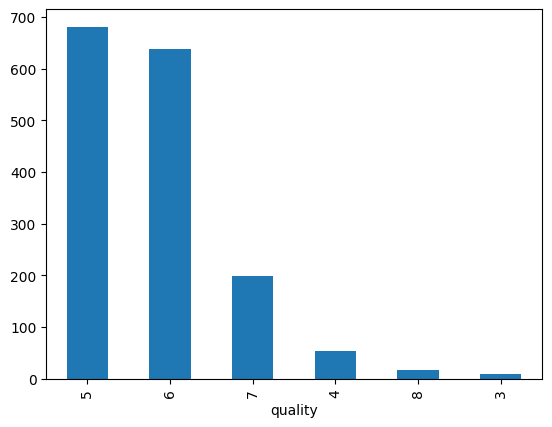

In [89]:
df['quality'].value_counts().plot(kind='bar')
plt.show()

In [90]:
df['quality'].value_counts()

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64

In [91]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


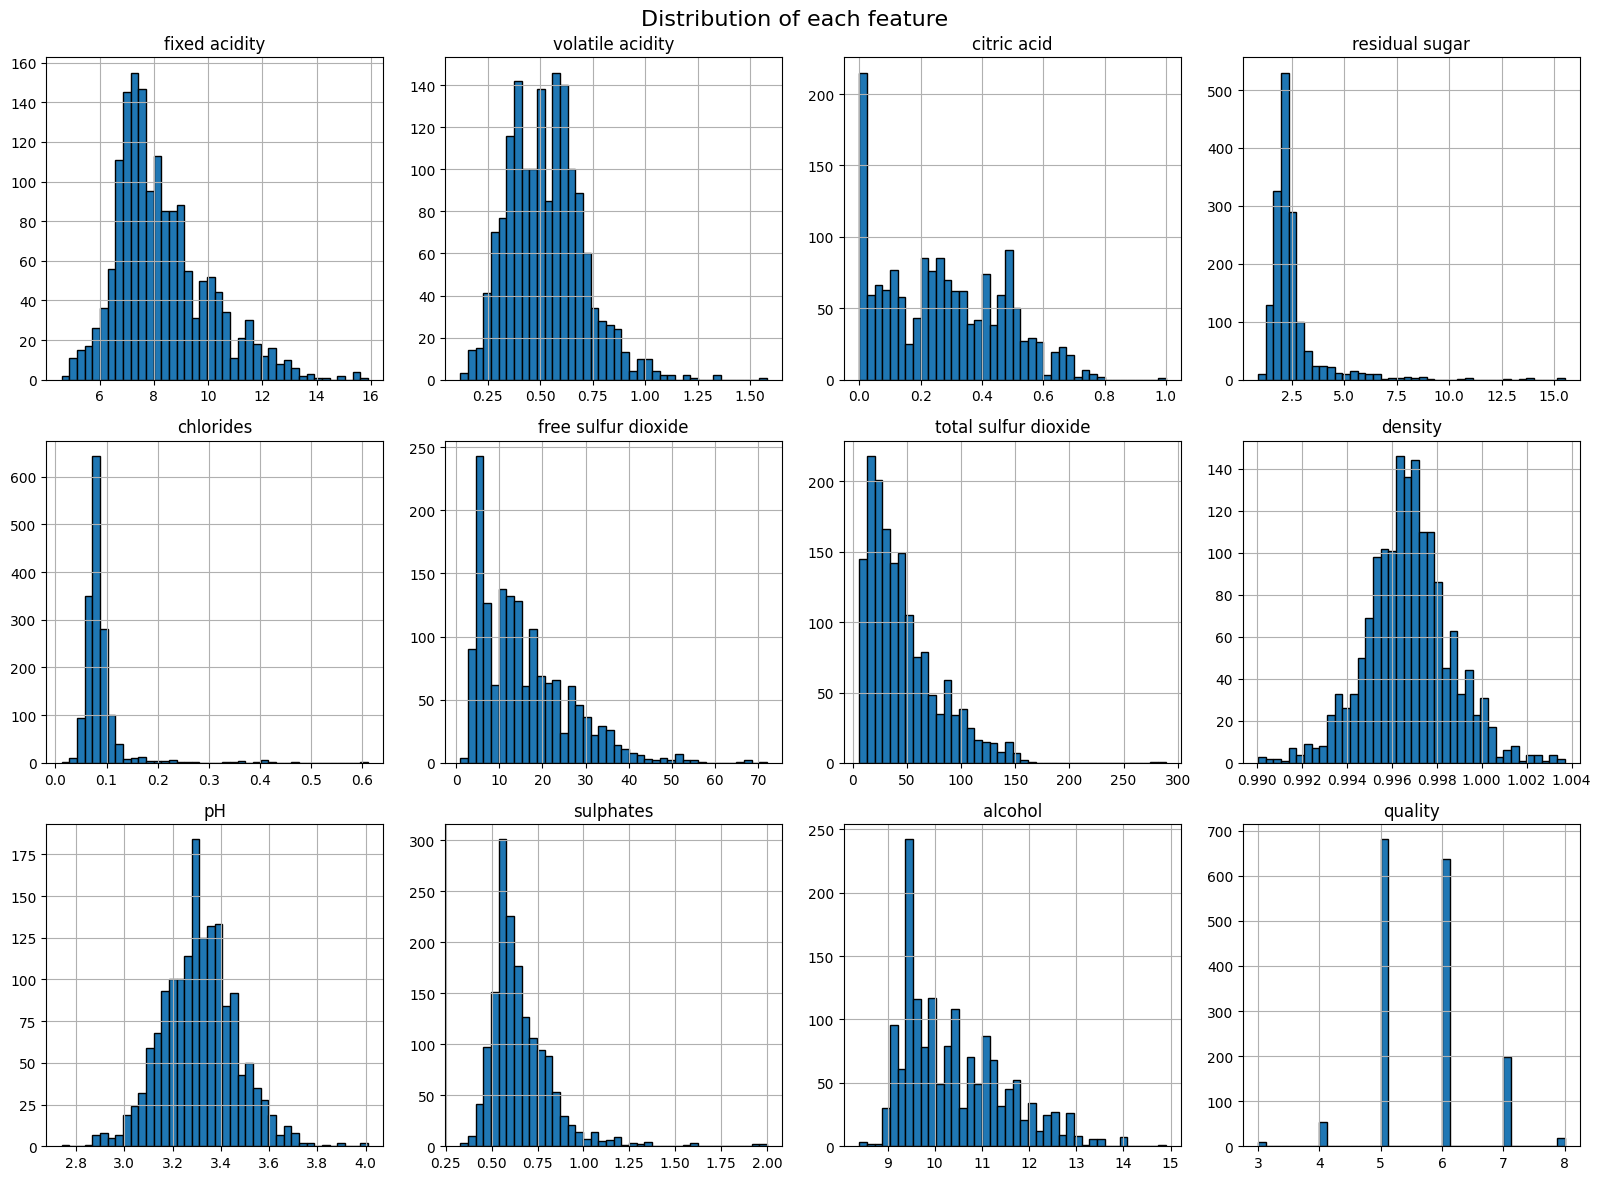

chlorides               5.680347
residual sugar          4.540655
sulphates               2.428672
total sulfur dioxide    1.515531
free sulfur dioxide     1.250567
fixed acidity           0.982751
alcohol                 0.860829
volatile acidity        0.671593
citric acid             0.318337
pH                      0.193683
density                 0.071288
dtype: float64


In [92]:
df.hist(bins=40, figsize=(16, 12), layout=(3, 4), edgecolor='black')
plt.suptitle('Distribution of each feature', fontsize=16)
plt.tight_layout()
plt.show()

skewness = df.drop('quality', axis=1).skew().sort_values(ascending=False)
print(skewness)

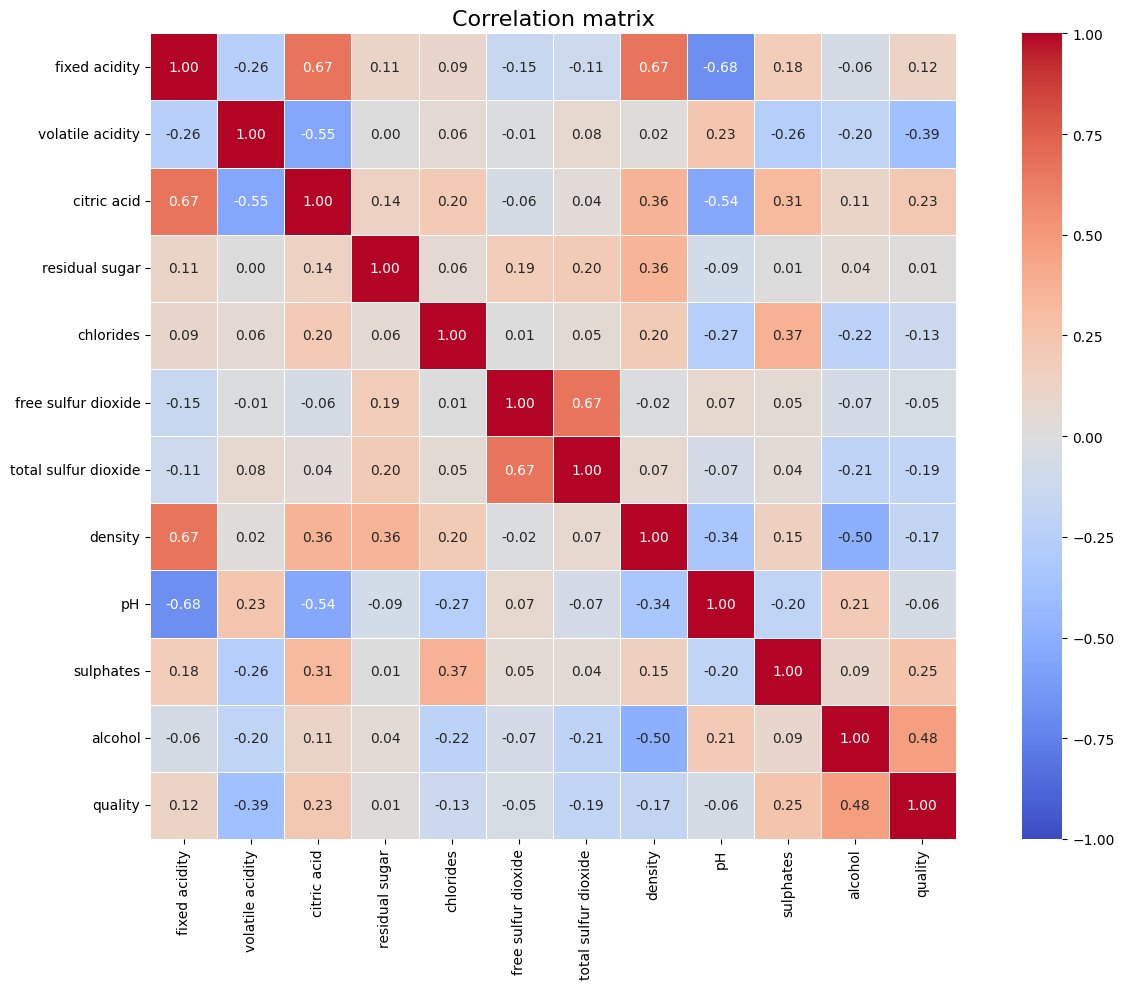

alcohol                 0.476166
volatile acidity       -0.390558
sulphates               0.251397
citric acid             0.226373
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
fixed acidity           0.124052
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
Name: quality, dtype: float64


In [93]:

corr = df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Correlation matrix', fontsize=16)
plt.tight_layout()
plt.show()

# Correlation of each feature with the target, sorted by strength
print(corr['quality'].drop('quality').sort_values(key=abs, ascending=False))

In [94]:
# Scatter plot: relationship between two features
def relate(col1, col2):
    plt.figure(figsize=(8, 5))
    plt.scatter(df[col1], df[col2], alpha=0.5, s=12)
    plt.xlabel(col1)
    plt.ylabel(col2)
    plt.title(f'{col1} vs {col2}')
    plt.show()

In [95]:
# Boxplot: quartiles and outliers of one feature
def boxp(col):
    plt.figure(figsize=(8, 5))
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.show()


In [96]:
# Boxplot of a feature grouped by the target
def boxp_by_quality(col):
    plt.figure(figsize=(8, 5))
    sns.boxplot(x='quality', y=col, data=df, hue='quality', palette='viridis', legend=False)
    plt.title(f'{col} by quality')
    plt.show()


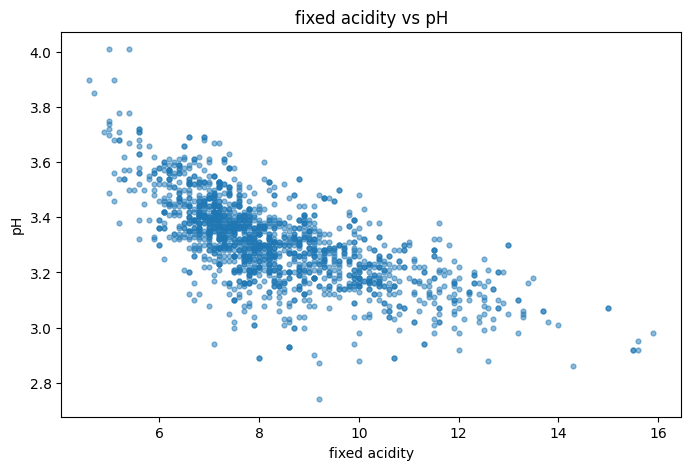

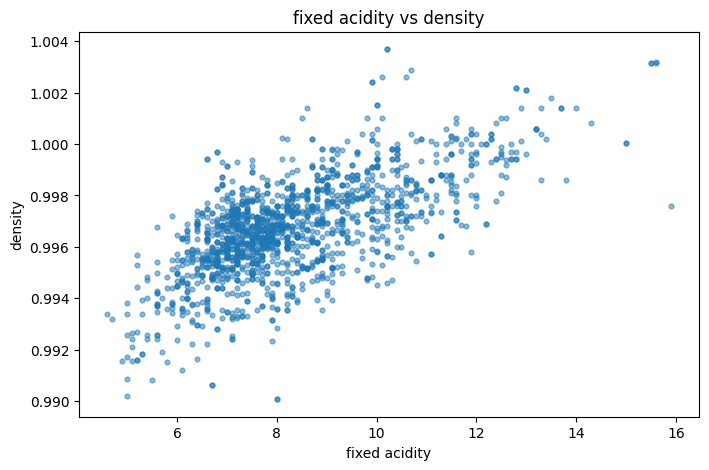

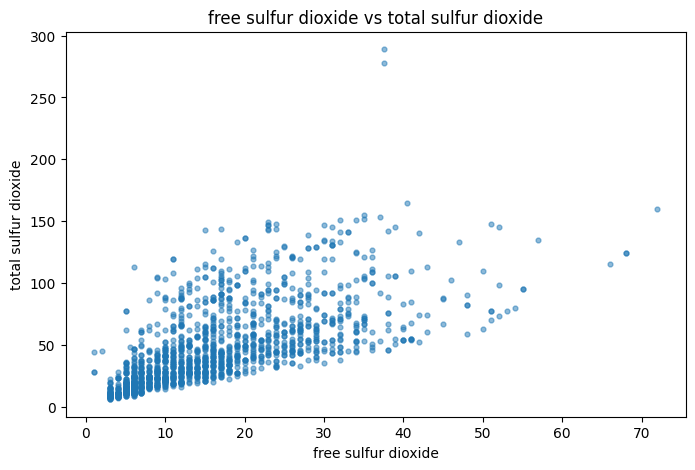

In [97]:
# Example uses: scatter plots of the strongly correlated pairs from 1.8
relate('fixed acidity', 'pH')
relate('fixed acidity', 'density')
relate('free sulfur dioxide', 'total sulfur dioxide')



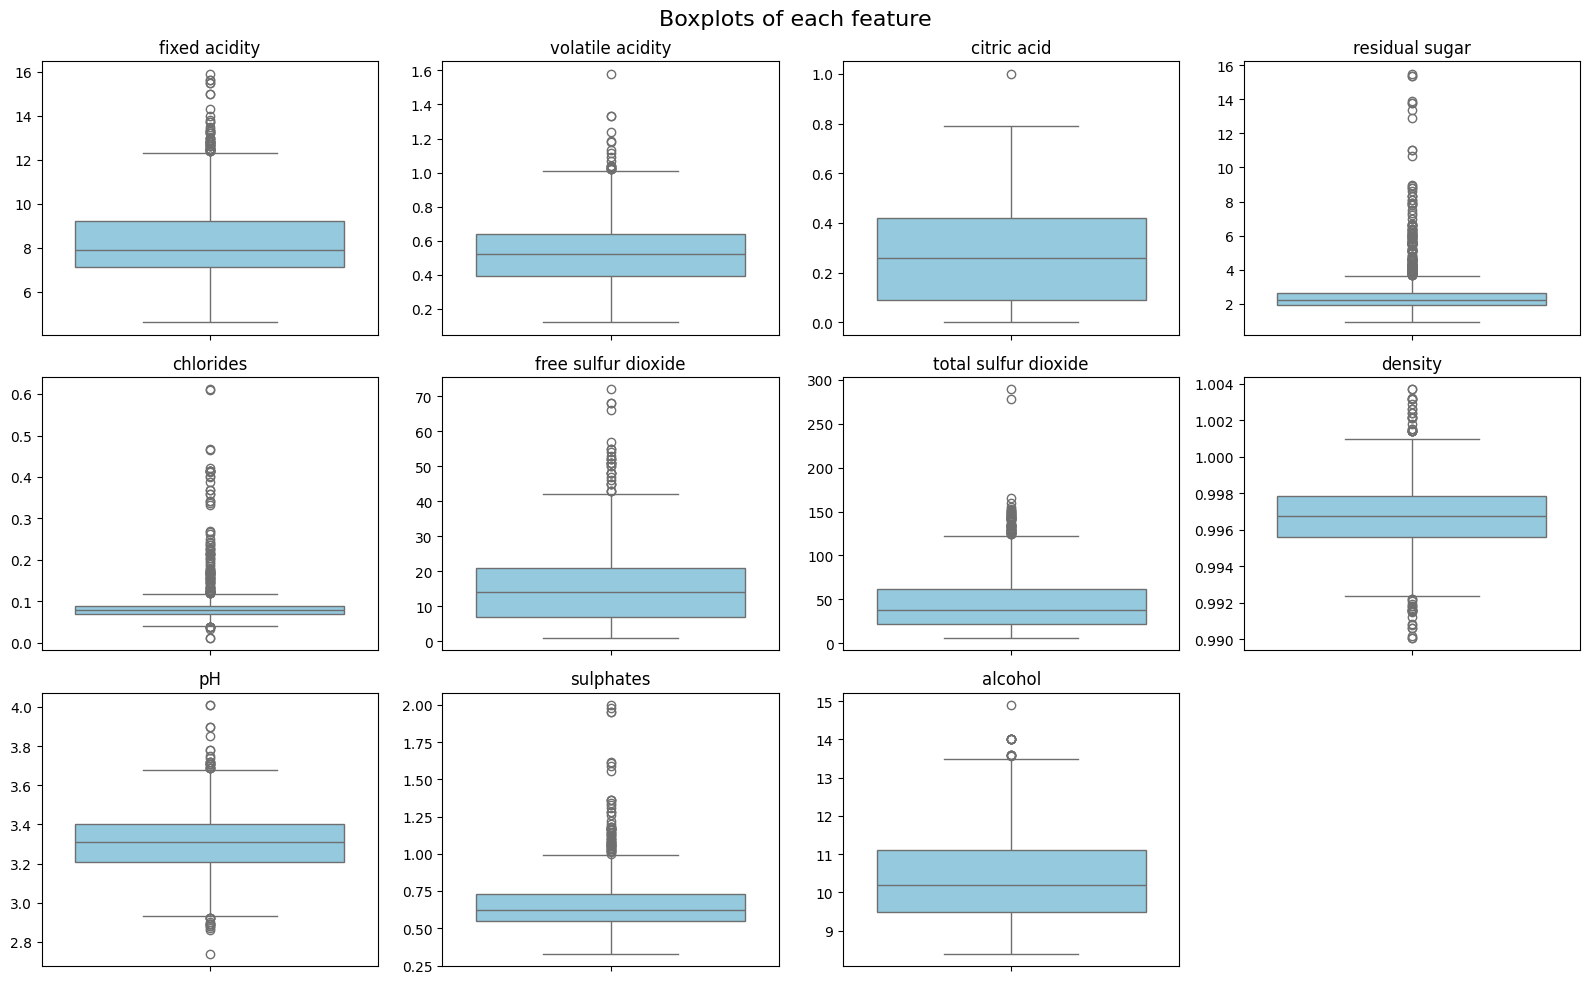

In [98]:
# Boxplots of all features in one figure
features = df.columns.drop('quality')
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, features):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
    ax.set_ylabel('')
axes.flat[-1].axis('off')
plt.suptitle('Boxplots of each feature', fontsize=16)
plt.tight_layout()
plt.show()



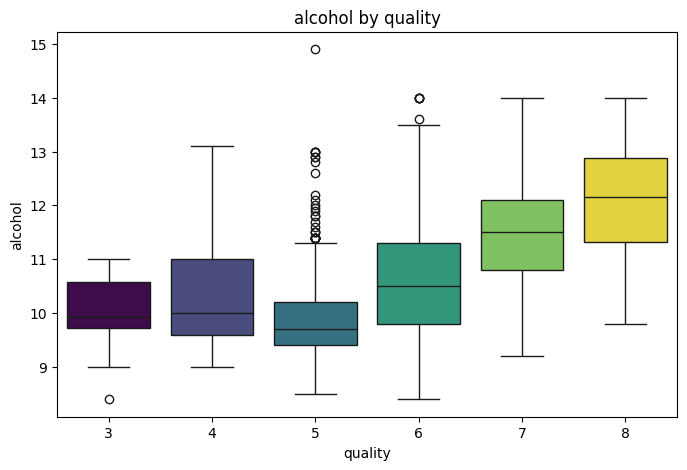

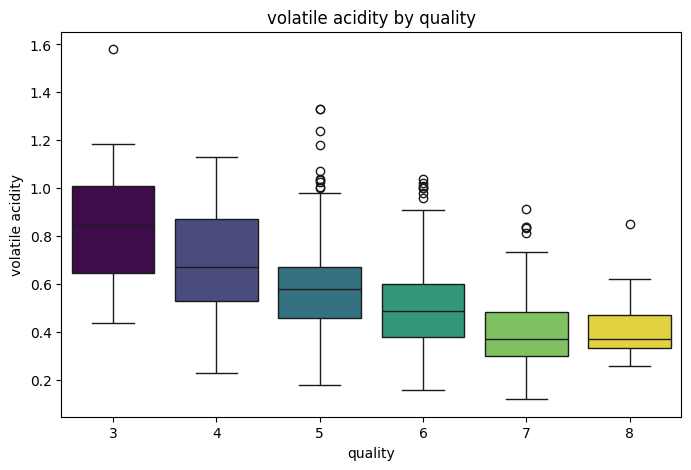

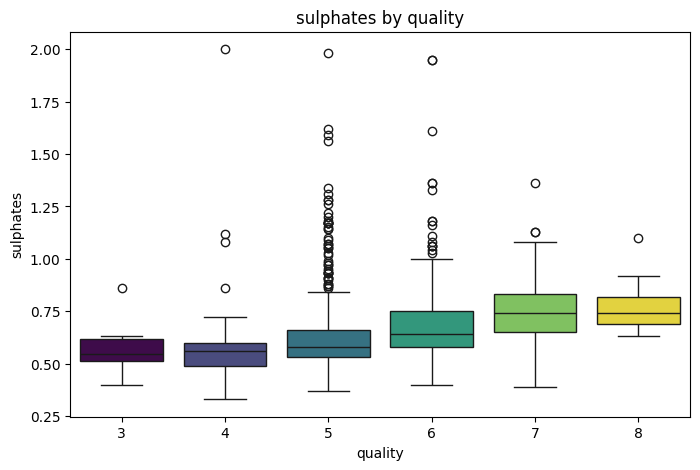

fixed acidity: 49 outliers (3.1%)
volatile acidity: 19 outliers (1.2%)
citric acid: 1 outliers (0.1%)
residual sugar: 155 outliers (9.7%)
chlorides: 112 outliers (7.0%)
free sulfur dioxide: 30 outliers (1.9%)
total sulfur dioxide: 55 outliers (3.4%)
density: 45 outliers (2.8%)
pH: 35 outliers (2.2%)
sulphates: 59 outliers (3.7%)
alcohol: 13 outliers (0.8%)


In [99]:
# The 3 features most related to quality
for col in ['alcohol', 'volatile acidity', 'sulphates']:
    boxp_by_quality(col)

# Count outliers with the IQR rule
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f'{col}: {n} outliers ({n / len(df) * 100:.1f}%)')

In [100]:
df.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [101]:
df.duplicated().sum()

np.int64(240)

In [102]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 240


In [103]:
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

df_clean = df.copy()   # clean copy used as the starting point for the next steps

Shape after removing duplicates: (1359, 12)


In [104]:
df.skew()

fixed acidity           0.941041
volatile acidity        0.729279
citric acid             0.312726
residual sugar          4.548153
chlorides               5.502487
free sulfur dioxide     1.226579
total sulfur dioxide    1.540368
density                 0.044778
pH                      0.232032
sulphates               2.406505
alcohol                 0.859841
quality                 0.192407
dtype: float64

chlorides               0.012
residual sugar          0.900
sulphates               0.330
total sulfur dioxide    6.000
free sulfur dioxide     1.000
fixed acidity           4.600
volatile acidity        0.120
alcohol                 8.400
dtype: float64
                      Before  After
chlorides               5.50   1.89
residual sugar          4.55   1.77
sulphates               2.41   0.96
total sulfur dioxide    1.54  -0.08
free sulfur dioxide     1.23  -0.22
fixed acidity           0.94   0.35
volatile acidity        0.73  -0.33
alcohol                 0.86   0.66


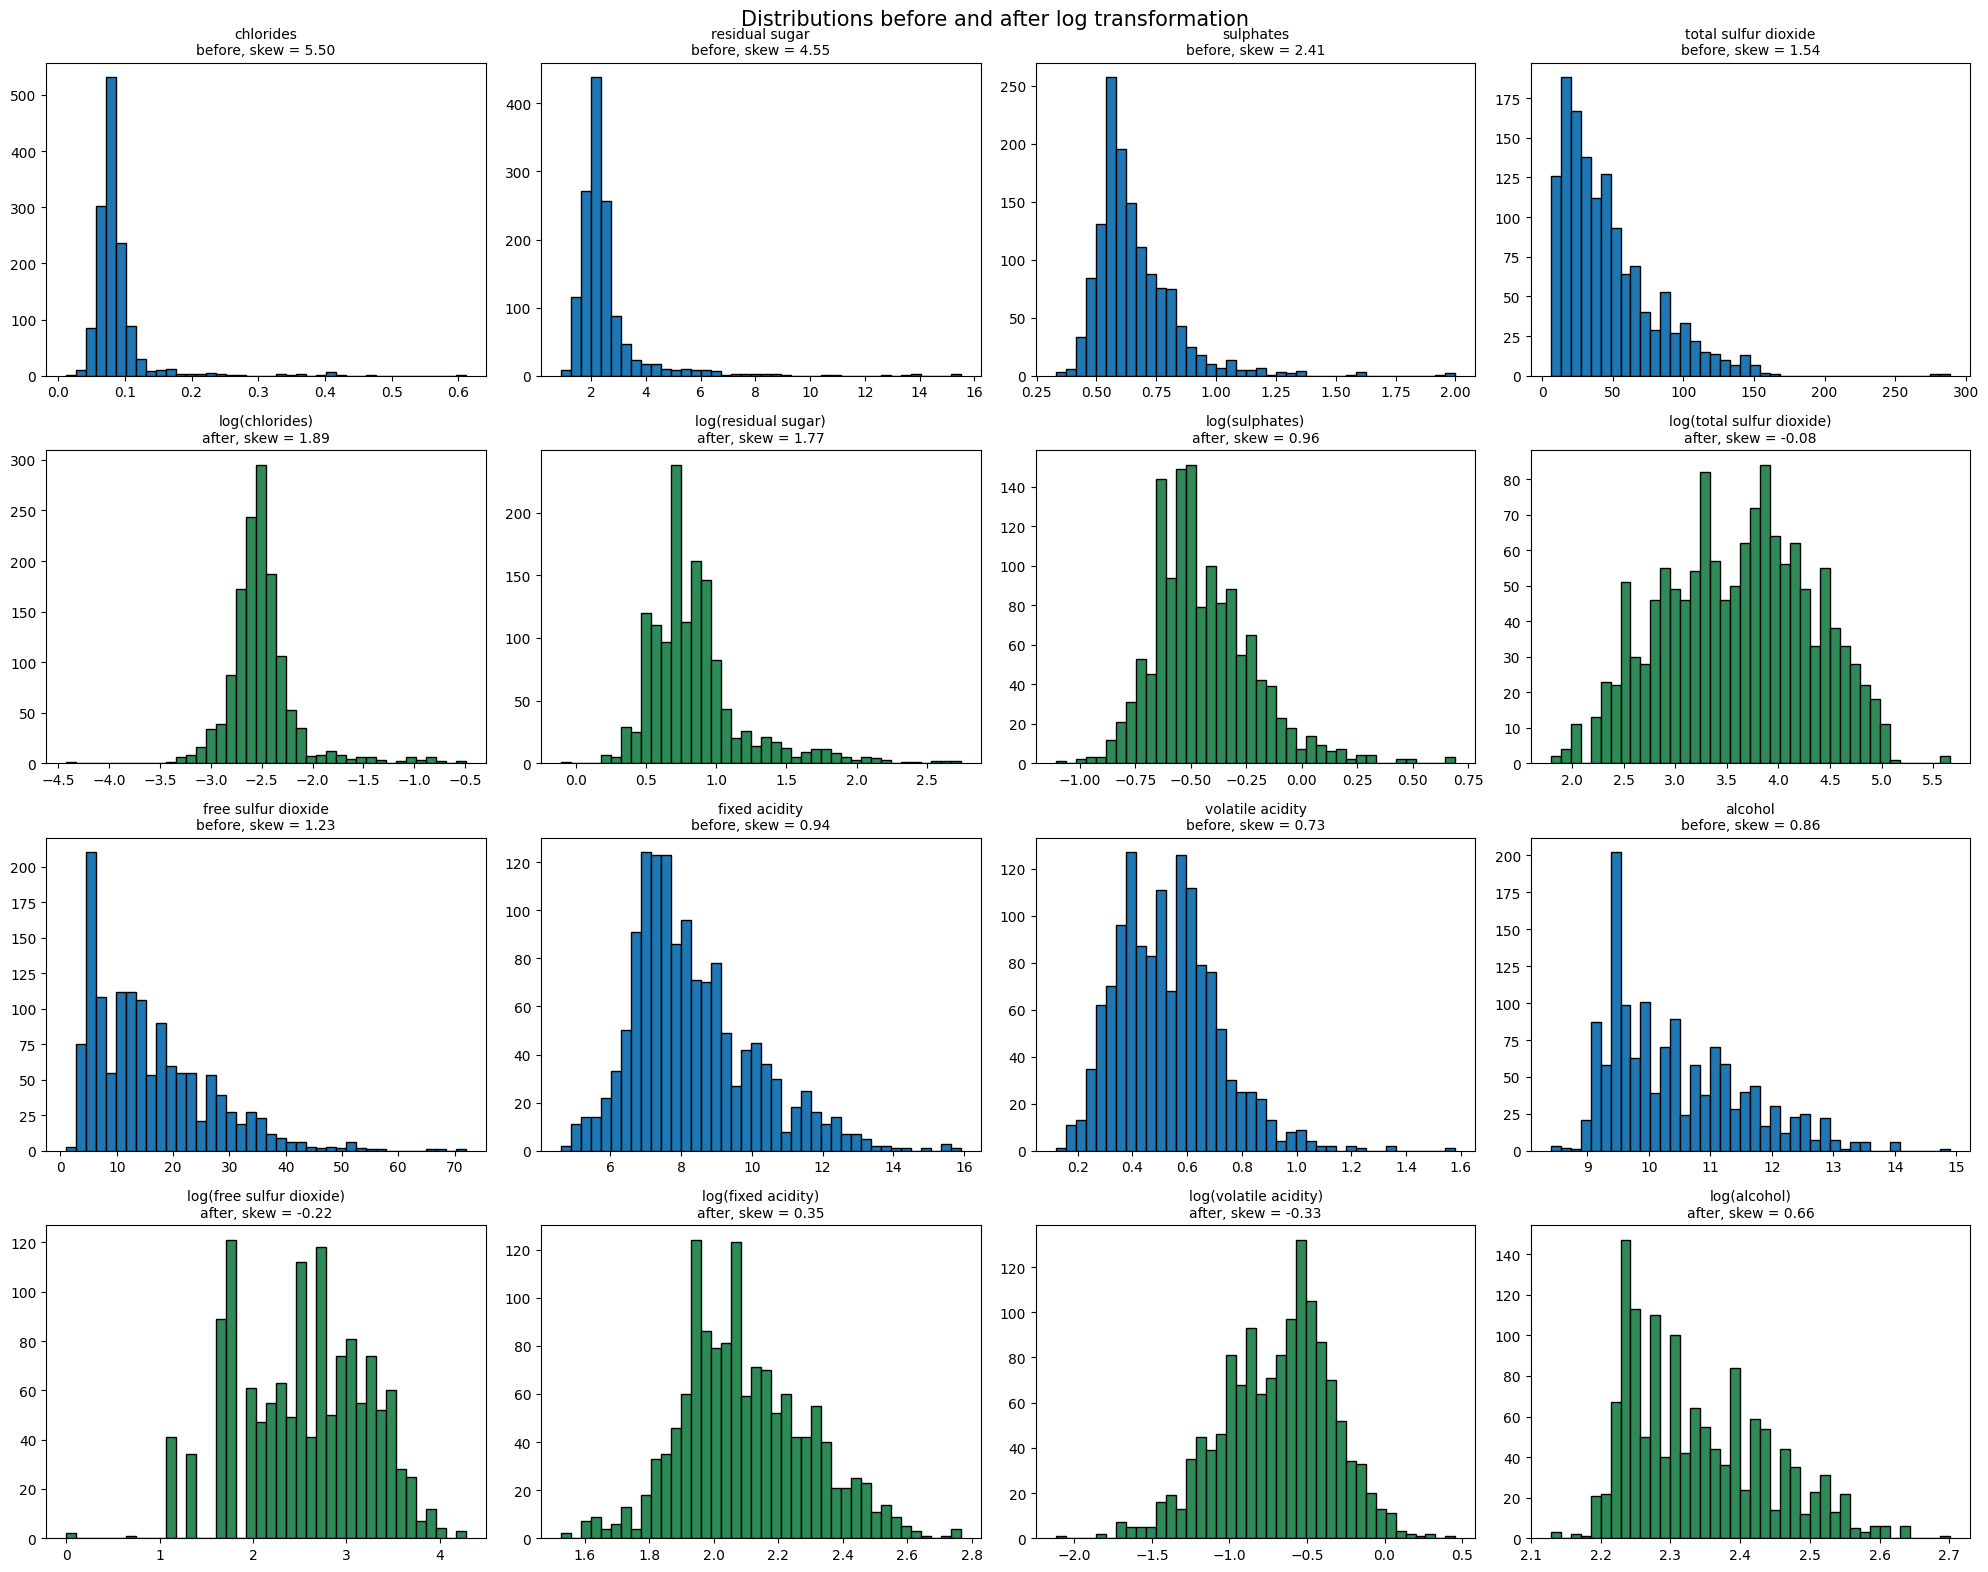

In [105]:
# 2.2 Normalisation (log transformation)

# Highly skewed (> 1) and moderately skewed (0.5 - 1) features
skewed_features = ['chlorides', 'residual sugar', 'sulphates',
                   'total sulfur dioxide', 'free sulfur dioxide',
                   'fixed acidity', 'volatile acidity', 'alcohol']

df_before = df_clean.copy()   # original values
df = df_clean.copy()          # always start from the clean data (safe to re-run)

print(df_before[skewed_features].min())   # all must be > 0

skew_before = df_before[skewed_features].skew()
for col in skewed_features:
    df[col] = np.log(df[col])
skew_after = df[skewed_features].skew()

print(pd.DataFrame({'Before': skew_before, 'After': skew_after}).round(2))

# Plot before vs after
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for i, col in enumerate(skewed_features):
    r, c = (i // 4) * 2, i % 4
    axes[r, c].hist(df_before[col], bins=40, edgecolor='black')
    axes[r, c].set_title(f'{col}\nbefore, skew = {skew_before[col]:.2f}', fontsize=10)
    axes[r + 1, c].hist(df[col], bins=40, edgecolor='black', color='seagreen')
    axes[r + 1, c].set_title(f'log({col})\nafter, skew = {skew_after[col]:.2f}', fontsize=10)
plt.suptitle('Distributions before and after log transformation', fontsize=15)
plt.tight_layout()
plt.show()

In [106]:
df = df_clean.copy()   # start from clean data (prevents the double-log problem)

df['chlorides'] = np.log(df['chlorides'])
df['residual sugar'] = np.log(df['residual sugar'])
df['sulphates'] = np.log(df['sulphates'])
df['total sulfur dioxide'] = np.log(df['total sulfur dioxide'])
df['free sulfur dioxide'] = np.log(df['free sulfur dioxide'])
df['fixed acidity'] = np.log(df['fixed acidity'])
df['volatile acidity'] = np.log(df['volatile acidity'])
df['alcohol'] = np.log(df['alcohol'])

df.skew()   # check the result

fixed acidity           0.348804
volatile acidity       -0.330795
citric acid             0.312726
residual sugar          1.765238
chlorides               1.887642
free sulfur dioxide    -0.220069
total sulfur dioxide   -0.078161
density                 0.044778
pH                      0.232032
sulphates               0.961460
alcohol                 0.663359
quality                 0.192407
dtype: float64

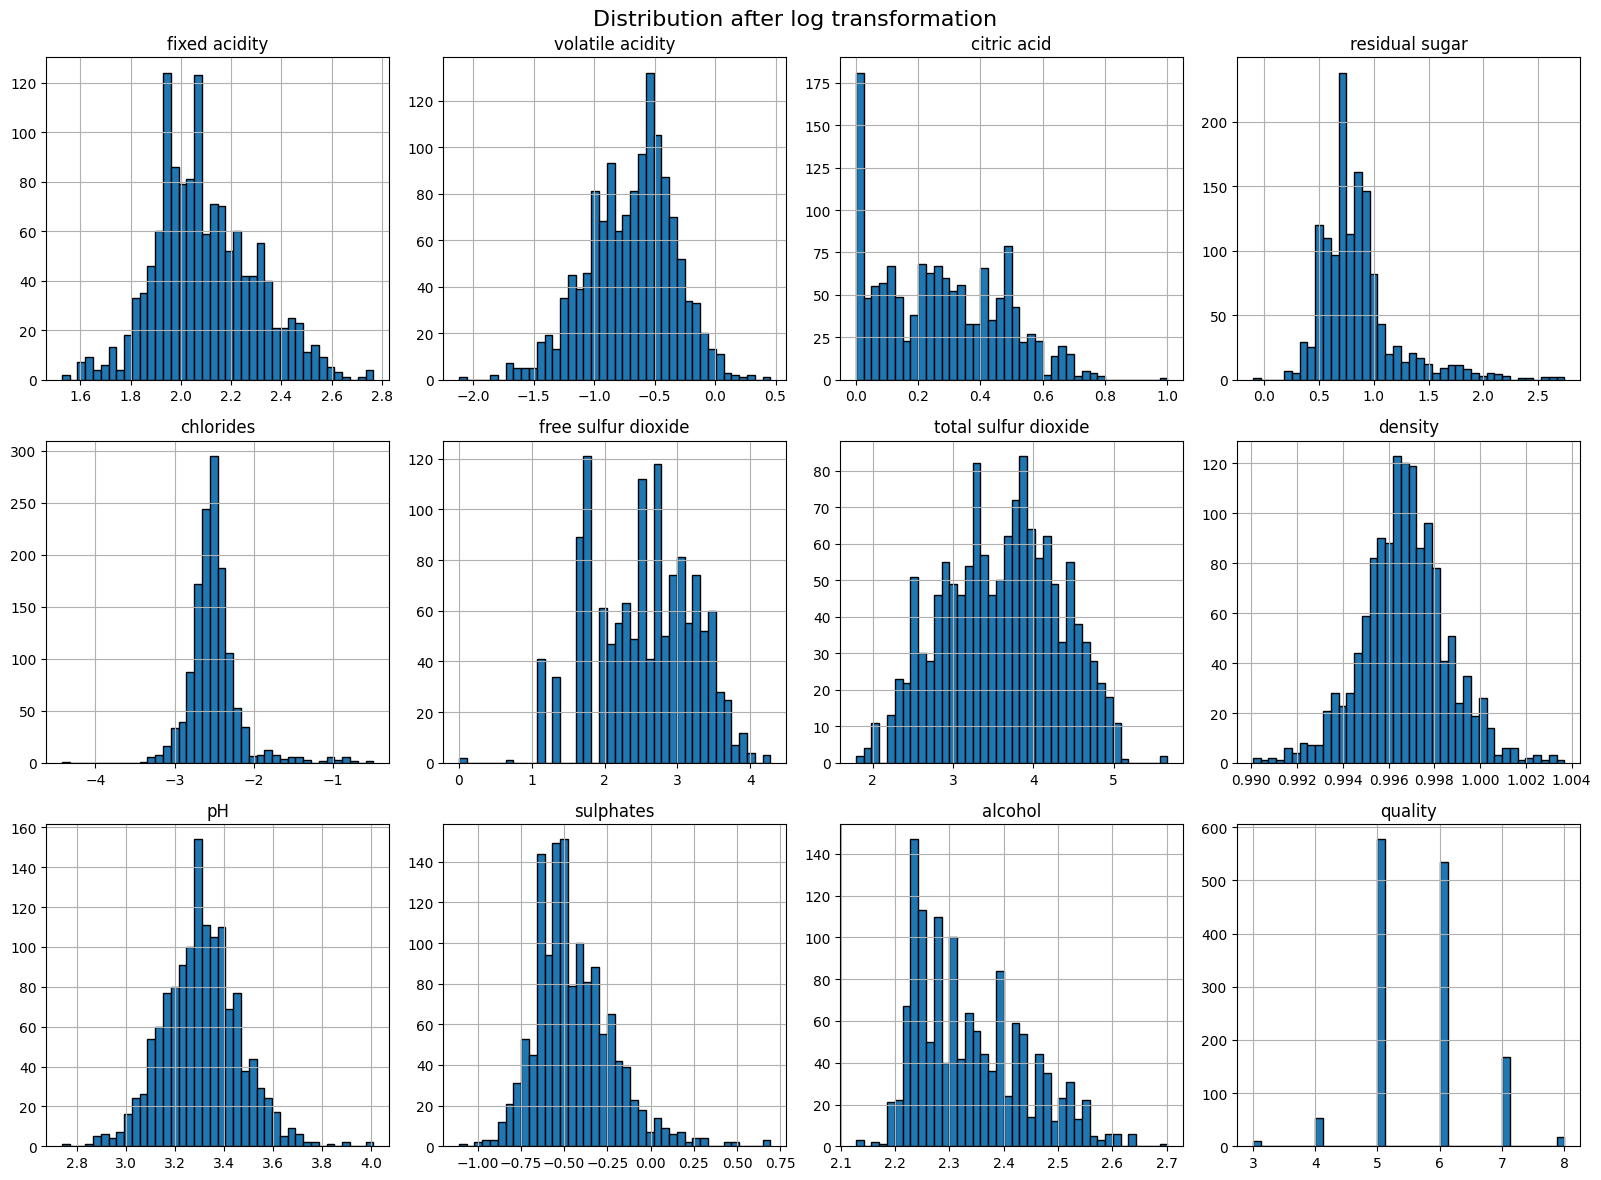

In [107]:
df.hist(bins=40, figsize=(16, 12), layout=(3, 4), edgecolor='black')
plt.suptitle('Distribution after log transformation', fontsize=16)
plt.tight_layout()
plt.show()

In [108]:
# 2.3 Treating outliers (IQR clipping)

def clip_outliers(column):
    data = df[column]
    q1 = np.percentile(data, 25)
    q3 = np.percentile(data, 75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return np.clip(data, lower_bound, upper_bound)

features = df.columns.drop('quality')   # never clip the target

# Count outliers and skewness BEFORE clipping
outliers_before = {}
skew_before = df[features].skew()
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers_before[col] = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()

# Apply clipping
df['fixed acidity'] = clip_outliers('fixed acidity')
df['volatile acidity'] = clip_outliers('volatile acidity')
df['citric acid'] = clip_outliers('citric acid')
df['residual sugar'] = clip_outliers('residual sugar')
df['chlorides'] = clip_outliers('chlorides')
df['free sulfur dioxide'] = clip_outliers('free sulfur dioxide')
df['total sulfur dioxide'] = clip_outliers('total sulfur dioxide')
df['density'] = clip_outliers('density')
df['pH'] = clip_outliers('pH')
df['sulphates'] = clip_outliers('sulphates')
df['alcohol'] = clip_outliers('alcohol')

# Results
summary = pd.DataFrame({
    'Outliers': pd.Series(outliers_before),
    'Skew before': skew_before,
    'Skew after': df[features].skew()
}).round(2)
print(summary)
print('Shape:', df.shape)

                      Outliers  Skew before  Skew after
fixed acidity               11         0.35        0.30
volatile acidity            11        -0.33       -0.29
citric acid                  1         0.31        0.31
residual sugar              96         1.77        0.59
chlorides                  102         1.89        0.17
free sulfur dioxide          2        -0.22       -0.20
total sulfur dioxide         0        -0.08       -0.08
density                     35         0.04        0.01
pH                          28         0.23        0.07
sulphates                   31         0.96        0.54
alcohol                      1         0.66        0.65
Shape: (1359, 12)


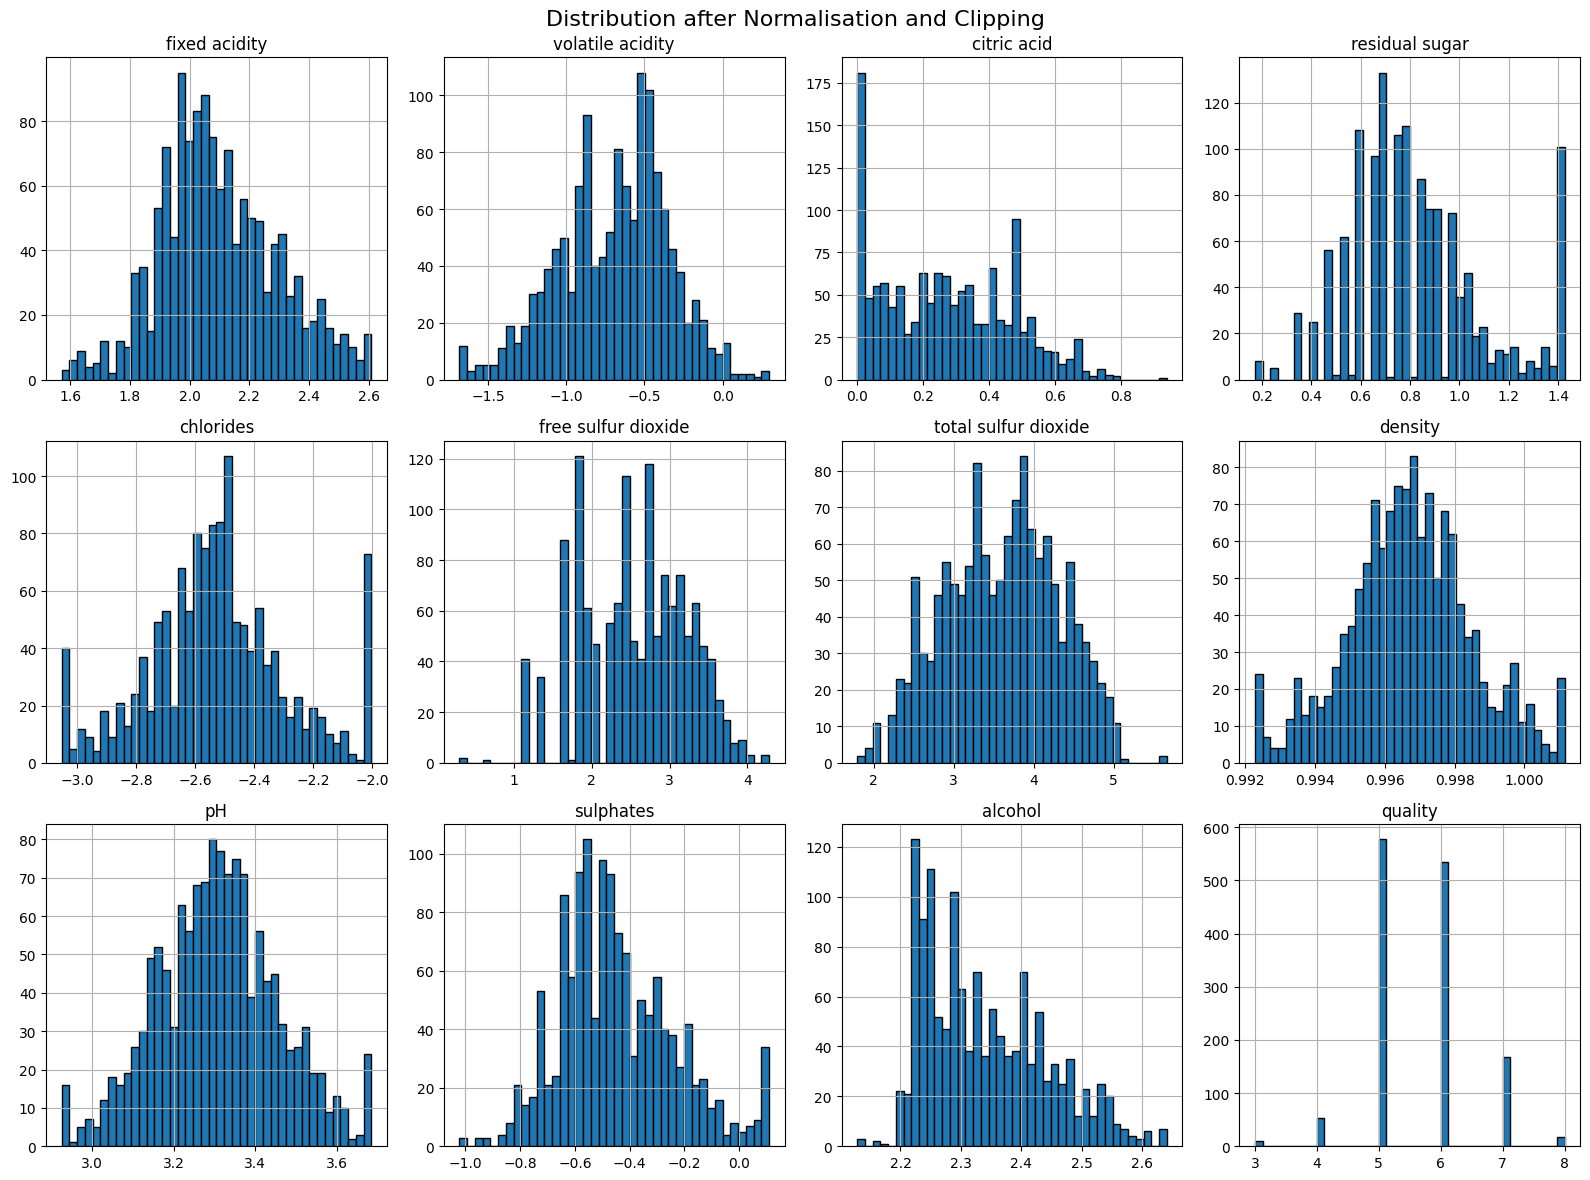

In [109]:
# 2.4 Visualising distribution after normalisation and clipping
df.hist(bins=40, figsize=(16, 12), layout=(3, 4), edgecolor='black')
plt.suptitle('Distribution after Normalisation and Clipping', fontsize=16)
plt.tight_layout()
plt.show()

In [115]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca = PCA(n_components=1)
feature_1 = ['fixed acidity', 'citric acid', 'density', 'pH']
feature_2 = ['free sulfur dioxide', 'total sulfur dioxide']

# standardise each group before PCA so every feature counts equally
pca_1 = pca.fit_transform(StandardScaler().fit_transform(df[feature_1]))
print('pca_1 explained variance:', pca.explained_variance_ratio_)

pca_2 = pca.fit_transform(StandardScaler().fit_transform(df[feature_2]))
print('pca_2 explained variance:', pca.explained_variance_ratio_)

df['pca_1'] = pca_1
df['pca_2'] = pca_2
df.info()

pca_1 explained variance: [0.67047126]
pca_2 explained variance: [0.89436845]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1359 entries, 0 to 1358
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1359 non-null   float64
 1   volatile acidity      1359 non-null   float64
 2   citric acid           1359 non-null   float64
 3   residual sugar        1359 non-null   float64
 4   chlorides             1359 non-null   float64
 5   free sulfur dioxide   1359 non-null   float64
 6   total sulfur dioxide  1359 non-null   float64
 7   density               1359 non-null   float64
 8   pH                    1359 non-null   float64
 9   sulphates             1359 non-null   float64
 10  alcohol               1359 non-null   float64
 11  quality               1359 non-null   int64  
 12  quality_class         1359 non-null   int64  
 13  pca_1                 1359 non-null   float64

In [116]:
# dropping columns which are used for PCA
df = df.drop(['fixed acidity', 'citric acid', 'density', 'pH',
              'free sulfur dioxide', 'total sulfur dioxide'], axis=1)

# rearranging columns
df = df[['volatile acidity', 'residual sugar', 'chlorides', 'sulphates',
         'alcohol', 'pca_1', 'pca_2', 'quality']]
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1359 entries, 0 to 1358
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   volatile acidity  1359 non-null   float64
 1   residual sugar    1359 non-null   float64
 2   chlorides         1359 non-null   float64
 3   sulphates         1359 non-null   float64
 4   alcohol           1359 non-null   float64
 5   pca_1             1359 non-null   float64
 6   pca_2             1359 non-null   float64
 7   quality           1359 non-null   int64  
dtypes: float64(7), int64(1)
memory usage: 85.1 KB


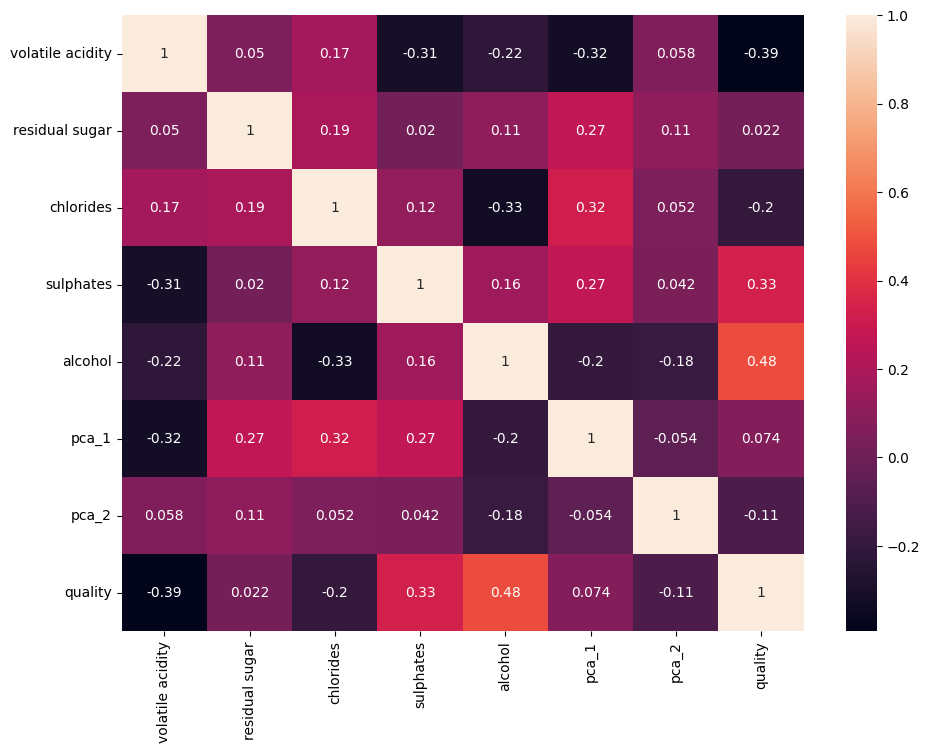

In [117]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), annot=True)
plt.show()

In [118]:
from sklearn.preprocessing import StandardScaler

# target: group quality into 3 classes (0 = low, 1 = medium, 2 = high)
y = pd.cut(df['quality'], bins=[2, 4, 6, 8], labels=[0, 1, 2]).astype(int)
X = df.drop('quality', axis=1)

scaler = StandardScaler()
X = scaler.fit_transform(X)

print(y.value_counts().sort_index())

quality
0      63
1    1112
2     184
Name: count, dtype: int64


In [119]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train classes:', y_train.value_counts().sort_index().tolist())
print('Test classes: ', y_test.value_counts().sort_index().tolist())

Train: (1087, 7)  Test: (272, 7)
Train classes: [50, 890, 147]
Test classes:  [13, 222, 37]


In [120]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

def model_report(y_test, y_pred):
    print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
    print('Classification Report:\n', classification_report(y_test, y_pred, zero_division=0))
    print('Accuracy:', round(accuracy_score(y_test, y_pred), 3))
    print('Macro F1-score:', round(f1_score(y_test, y_pred, average='macro'), 3))

In [121]:
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)
model_report(y_test, gb_pred)

Confusion Matrix:
 [[  0  13   0]
 [  0 208  14]
 [  0  16  21]]
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        13
           1       0.88      0.94      0.91       222
           2       0.60      0.57      0.58        37

    accuracy                           0.84       272
   macro avg       0.49      0.50      0.50       272
weighted avg       0.80      0.84      0.82       272

Accuracy: 0.842
Macro F1-score: 0.497


In [122]:
svm_model = SVC(random_state=42)   # default: kernel='rbf', C=1
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
model_report(y_test, svm_pred)

Confusion Matrix:
 [[  0  13   0]
 [  0 217   5]
 [  0  22  15]]
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        13
           1       0.86      0.98      0.92       222
           2       0.75      0.41      0.53        37

    accuracy                           0.85       272
   macro avg       0.54      0.46      0.48       272
weighted avg       0.80      0.85      0.82       272

Accuracy: 0.853
Macro F1-score: 0.481


In [123]:
rfc = RandomForestClassifier(random_state=42)
rfc.fit(X_train, y_train)
rfc_pred = rfc.predict(X_test)
model_report(y_test, rfc_pred)

Confusion Matrix:
 [[  0  13   0]
 [  0 215   7]
 [  0  22  15]]
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        13
           1       0.86      0.97      0.91       222
           2       0.68      0.41      0.51        37

    accuracy                           0.85       272
   macro avg       0.51      0.46      0.47       272
weighted avg       0.79      0.85      0.81       272

Accuracy: 0.846
Macro F1-score: 0.473


In [124]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {'Random Forest': RandomForestClassifier(random_state=42),
          'Gradient Boosting': GradientBoostingClassifier(random_state=42),
          'SVM': SVC(random_state=42)}

print('Cross Validation Scores')
for name, model in models.items():
    acc = cross_val_score(model, X, y, cv=skf, scoring='accuracy')
    f1  = cross_val_score(model, X, y, cv=skf, scoring='f1_macro')
    print(f'{name}: accuracy {acc.round(3)} Avg: {acc.mean():.3f} | '
          f'macro F1 {f1.round(3)} Avg: {f1.mean():.3f}')

Cross Validation Scores
Random Forest: accuracy [0.838 0.842 0.835 0.835 0.823] Avg: 0.834 | macro F1 [0.451 0.458 0.445 0.496 0.456] Avg: 0.461
Gradient Boosting: accuracy [0.824 0.827 0.809 0.838 0.804] Avg: 0.820 | macro F1 [0.457 0.456 0.454 0.556 0.423] Avg: 0.469
SVM: accuracy [0.831 0.842 0.838 0.846 0.827] Avg: 0.837 | macro F1 [0.399 0.444 0.433 0.448 0.404] Avg: 0.426


In [125]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.utils.class_weight import compute_sample_weight

In [126]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced']
}
random_search = RandomizedSearchCV(RandomForestClassifier(random_state=42), param_dist,
                                   n_iter=30, scoring='f1_macro', cv=skf,
                                   random_state=42, n_jobs=-1)
random_search.fit(X_train, y_train)
print('Best Parameters:', random_search.best_params_)
print('Best CV macro F1:', round(random_search.best_score_, 3))

rf_rs_pred = random_search.best_estimator_.predict(X_test)
model_report(y_test, rf_rs_pred)

Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 5, 'class_weight': 'balanced'}
Best CV macro F1: 0.523
Confusion Matrix:
 [[  6   7   0]
 [ 12 171  39]
 [  0  10  27]]
Classification Report:
               precision    recall  f1-score   support

           0       0.33      0.46      0.39        13
           1       0.91      0.77      0.83       222
           2       0.41      0.73      0.52        37

    accuracy                           0.75       272
   macro avg       0.55      0.65      0.58       272
weighted avg       0.81      0.75      0.77       272

Accuracy: 0.75
Macro F1-score: 0.582


In [127]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced']
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid,
                           scoring='f1_macro', cv=skf, n_jobs=-1)
grid_search.fit(X_train, y_train)
print('Best Parameters:', grid_search.best_params_)
print('Best CV macro F1:', round(grid_search.best_score_, 3))

rf_gs_pred = grid_search.best_estimator_.predict(X_test)
model_report(y_test, rf_gs_pred)

Best Parameters: {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 2, 'n_estimators': 100}
Best CV macro F1: 0.528
Confusion Matrix:
 [[  6   7   0]
 [ 12 171  39]
 [  0  10  27]]
Classification Report:
               precision    recall  f1-score   support

           0       0.33      0.46      0.39        13
           1       0.91      0.77      0.83       222
           2       0.41      0.73      0.52        37

    accuracy                           0.75       272
   macro avg       0.55      0.65      0.58       272
weighted avg       0.81      0.75      0.77       272

Accuracy: 0.75
Macro F1-score: 0.582


In [128]:
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear'],
    'class_weight': [None, 'balanced']
}
grid_svm = GridSearchCV(SVC(random_state=42), param_grid_svm,
                        scoring='f1_macro', cv=skf, n_jobs=-1)
grid_svm.fit(X_train, y_train)
print('Best Parameters:', grid_svm.best_params_)
print('Best CV macro F1:', round(grid_svm.best_score_, 3))

svm_gs_pred = grid_svm.best_estimator_.predict(X_test)
model_report(y_test, svm_gs_pred)

Best Parameters: {'C': 100, 'class_weight': None, 'gamma': 0.1, 'kernel': 'rbf'}
Best CV macro F1: 0.5
Confusion Matrix:
 [[  4   8   1]
 [  9 201  12]
 [  1  18  18]]
Classification Report:
               precision    recall  f1-score   support

           0       0.29      0.31      0.30        13
           1       0.89      0.91      0.90       222
           2       0.58      0.49      0.53        37

    accuracy                           0.82       272
   macro avg       0.58      0.57      0.57       272
weighted avg       0.82      0.82      0.82       272

Accuracy: 0.82
Macro F1-score: 0.574


In [129]:
param_grid_gb = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3, 4]
}
weights = compute_sample_weight('balanced', y_train)
grid_gb = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid_gb,
                       scoring='f1_macro', cv=skf, n_jobs=-1)
grid_gb.fit(X_train, y_train, sample_weight=weights)
print('Best Parameters:', grid_gb.best_params_)
print('Best CV macro F1:', round(grid_gb.best_score_, 3))

gb_gs_pred = grid_gb.best_estimator_.predict(X_test)
model_report(y_test, gb_gs_pred)

Best Parameters: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
Best CV macro F1: 0.602
Confusion Matrix:
 [[  7   6   0]
 [ 22 149  51]
 [  0   7  30]]
Classification Report:
               precision    recall  f1-score   support

           0       0.24      0.54      0.33        13
           1       0.92      0.67      0.78       222
           2       0.37      0.81      0.51        37

    accuracy                           0.68       272
   macro avg       0.51      0.67      0.54       272
weighted avg       0.81      0.68      0.72       272

Accuracy: 0.684
Macro F1-score: 0.539


In [130]:
results = {
    'Gradient Boosting (default)': gb_pred,
    'SVM (default)': svm_pred,
    'Random Forest (default)': rfc_pred,
    'Random Forest (RandomizedSearch)': rf_rs_pred,
    'Random Forest (GridSearch)': rf_gs_pred,
    'SVM (GridSearch)': svm_gs_pred,
    'Gradient Boosting (GridSearch)': gb_gs_pred
}
summary = pd.DataFrame({
    'Accuracy': {k: accuracy_score(y_test, v) for k, v in results.items()},
    'Macro F1': {k: f1_score(y_test, v, average='macro') for k, v in results.items()}
}).round(3).sort_values('Macro F1', ascending=False)
summary

,Accuracy,Macro F1
Random Forest (RandomizedSearch),0.750,0.582
Random Forest (GridSearch),0.750,0.582
SVM (GridSearch),0.820,0.574
Gradient Boosting (GridSearch),0.684,0.539
Gradient Boosting (default),0.842,0.497
SVM (default),0.853,0.481
Random Forest (default),0.846,0.473


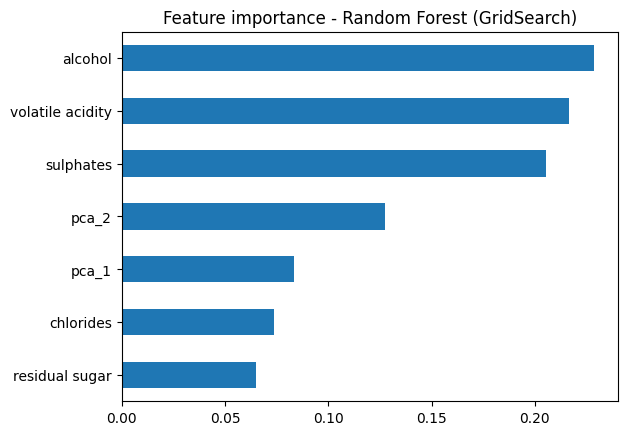

In [131]:
feature_names = df.drop('quality', axis=1).columns
importance = pd.Series(grid_search.best_estimator_.feature_importances_,
                       index=feature_names).sort_values()
importance.plot(kind='barh', title='Feature importance - Random Forest (GridSearch)')
plt.show()